# Simulation: Source Spike with Propagation

Explain simulation please

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path
import numpy as np
import shutil

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: EEG template
- `fwd`: Forward solution
- `sc`: Structural connectome
- `parc`: Parcellation
- `cras`: Transformation (MRI -> RAS)
- `white`: Inner cortical surface
- `hmodel`: Head conductor model 
- `cst`: Connectome spectrum transform
- `ctx`: Cortical mask

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject template.

🛠️ **<font color=violet>Meta-data</font>**:
- `name`: dataset name
- `folder`: location to put dataset folder
- `N`: number of samples

🛠️ **<font color=violet>Source Spike</font>**:
- `duration`: duration of the simulation in [s] (fix)
- `stype`: spike type (fix)
    - "mex": mexican hat
    - "ham": double ham
- `amplitude`: maximum amplitude of spike in [A] (fix or range)
- `width`: duration of the spike (...)
- `location`: location of the source spike given by a brain region (list(str) or 'random')

🛠️ **<font color=violet>Spike Propagation</font>**:
- `dw`: Propagation weight [0-1] (fix or range)
- `dt`: Propagation delay in [ms] (fix or range)

🛠️ **<font color=violet>Noise Generation</font>**:
- `target_snr`: Maximum EEG SNR in [dB] expcted (fix or range)
- `ratio`: Ratio [0-1] between brain noise and EEG electrical noise. (fix or range)

🛠️ **<font color=violet>Other options</font>**:
- `overwrite`: Overwrite dataset if dataset with same name at location already exists.

In [2]:
############## Parameters ###############
# configuration
fconfig = "../configurations/simf.yml"
sub     = 0

# meta-data
name   = "simulations"
folder = "/media/nino/DATA/SIMF/derivatives"
N      = 5

# source spike
duration  = 1
stype     = "mex"
amplitude = 1e-8
width     = None
location  = "random" 

# spike propagation 
dw = 0 
dt = 50

# noise generation 
target_snr = 20 
ratio = 0.9

# other options
overwrite = True 
##########################################

# configuration
config = mm.io.read_config(fconfig)
sub    = config["SUBS"][sub]
folder = Path(folder + "/" + name)

# create txt

## ♾️ Loop

📤 **<font color=pink>Outputs</font>**
- Dataset of simulated data.

In [3]:
# check existence of folder
if folder.exists():
    if overwrite:
        shutil.rmtree(folder)
    else:
        raise FileExistsError(f"Folder with name '{name}' already exists at location '{folder.parent}'")
folder.mkdir()
(folder/"eeg").mkdir()
(folder/"stc").mkdir()


# data 
data = mm.io.read_dataset(sub, "eeg", "fwd", "sc", "parc", "cras")

# determine parameters for each simulation
param = dict(amp=amplitude, dw=dw, dt=dt, snr=target_snr, r=ratio)
for k, i in param.items():
    if isinstance(i, list):
        param[k] = np.random.uniform(i[0], i[1], N)
    else:
        param[k] = [i]*N

if location == "random":
    location = list(data["parc"].get_clut()["Label name"])
elif isinstance(location, str):
    location = [location]

param["loc"] = list(np.random.choice(location, N, replace=True))


# loop through number of samples
for i in range(N):
    # create spike
    spike = mm.utils.create_source_spike(
        duration  = duration,
        sfreq     = data["eeg"].info["sfreq"],
        stype     = stype,
        amplitude = param["amp"][i]
    )

    # propagate spike
    spike_activity = mm.utils.generate_spike_activity(
        src      = data["fwd"]["src"],
        sc       = data["sc"],
        parc     = data["parc"],
        spike    = spike,
        location = param["loc"][i], 
        dw       = param["dw"][i],
        dt       = param["dt"][i],
        sfreq    = data["eeg"].info["sfreq"],
        cras     = data["cras"],
    )

    # generate noise
    brain_noise, eeg_noise = mm.utils.generate_scaled_noise(
        data       = spike_activity,
        fwd        = data["fwd"],
        target_snr = param["snr"][i],
        ratio      = param["r"][i],
    )

    # generate EEG
    brain, eeg = mm.utils.simulate_eeg(
        brain_activity = spike_activity,
        fwd            = data["fwd"],
        eeg_temp       = data["eeg"],
        brain_noise    = brain_noise, 
        eeg_noise      = eeg_noise,
        sub            = sub,
    )

    # save 
    feeg   = folder/"eeg"/f"{sub}-sample{i+1:03}_ave.fif"
    fbrain = folder/"stc"/f"{sub}-sample{i+1:03}_stc.fif"

    eeg.save(feeg, verbose="warning")
    brain.save(fbrain, verbose="warning")

print(f"\033[92mSuccessfully generated new dataset: '{name}'\033[0m")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- parc
- sc
- fwd
- eeg
- cras
Missing objects:
Successfully generated new dataset: 'simulations'


# Step Wise Run

Run the code step by step for a single simulation.

## 📦 Imports

In [1]:
import mindmap as mm 
import pyvista as pv
import pywt
import numpy as np
import mne
import seaborn as sns
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `eeg`: EEG template
- `fwd`: Forward solution
- `sc`: Structural connectome
- `parc`: Parcellation
- `cras`: Transformation (MRI -> RAS)
- `white`: Inner cortical surface
- `hmodel`: Head conductor model 
- `cst`: Connectome spectrum transform
- `ctx`: Cortical mask

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id (position in list SUBS)

In [2]:
############### Parameters #################
fconfig = "../configurations/simf.yml"
sub     = 0
############################################

# configuration
config = mm.io.read_config("../configurations/simf.yml")
sub    = config["SUBS"][sub]

# data
data  = mm.io.read_dataset(sub, "eeg", "fwd", "sc", "parc", "cras", "white", "bem", "cst", "ctx")

# forward matrix
A = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
A = A["sol"]["data"]

# region label of dipoles
regions = data["parc"].get_clut()["Label name"].values                                                  # region ids
pos     = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels  = data["parc"].label_points(pos)                                                                # dipole labels

# eeg meta-data
sfreq = data["eeg"].info["sfreq"]
time  = data["eeg"].times

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- parc
- eeg
- ctx
- bem
- cst
- sc
- fwd
- white
- cras
Missing objects:


## Simulation

#### ⚙️ **<font color=green>Generate simulation</font>**
🛠️ **<font color=violet>Source Spike</font>**:
- `duration`: duration of the simulation
- `stype`: spike type
    - "mex": mexican hat
    - "ham": double ham
- `amplitude`: maximum amplitude of spike
- `width`: duration of the spike
- `location`: location of the source spike given by a brain region

🛠️ **<font color=violet>Spike Propagation</font>**:
- `dw`: Propagation weight [0-1]
- `dt`: Propagation delay in [ms]

🛠️ **<font color=violet>Noise Generation</font>**:
- `target_snr`: Maximum EEG SNR in [dB] expcted
- `ratio`: Ratio [0-1] between brain noise and EEG electrical noise.

In [4]:

########################### Parameters #############################
# Source Spike
duration  = 1
stype     = "mex"
amplitude = 1e-8
width     = None
location  = "random"

# Spike Propagation
dw = 0.25 
dt = 50

# Noise Generation
target_snr = 15
ratio      = 0.9
######################################################################


spike          = mm.utils.create_source_spike(duration, sfreq, stype, amplitude)
spike_activity = mm.utils.generate_spike_activity(data["fwd"]["src"], data["sc"], data["parc"], spike, dw=dw, dt=dt, sfreq=sfreq, cras=data["cras"])

brain_noise, eeg_noise = mm.utils.generate_scaled_noise(spike_activity, data["fwd"], target_snr, ratio, bn_type="pink")
brain, eeg             = mm.utils.simulate_eeg(spike_activity, data["fwd"], data["eeg"], brain_noise, eeg_noise, sub)

#### 🌟 Visualize Time Series

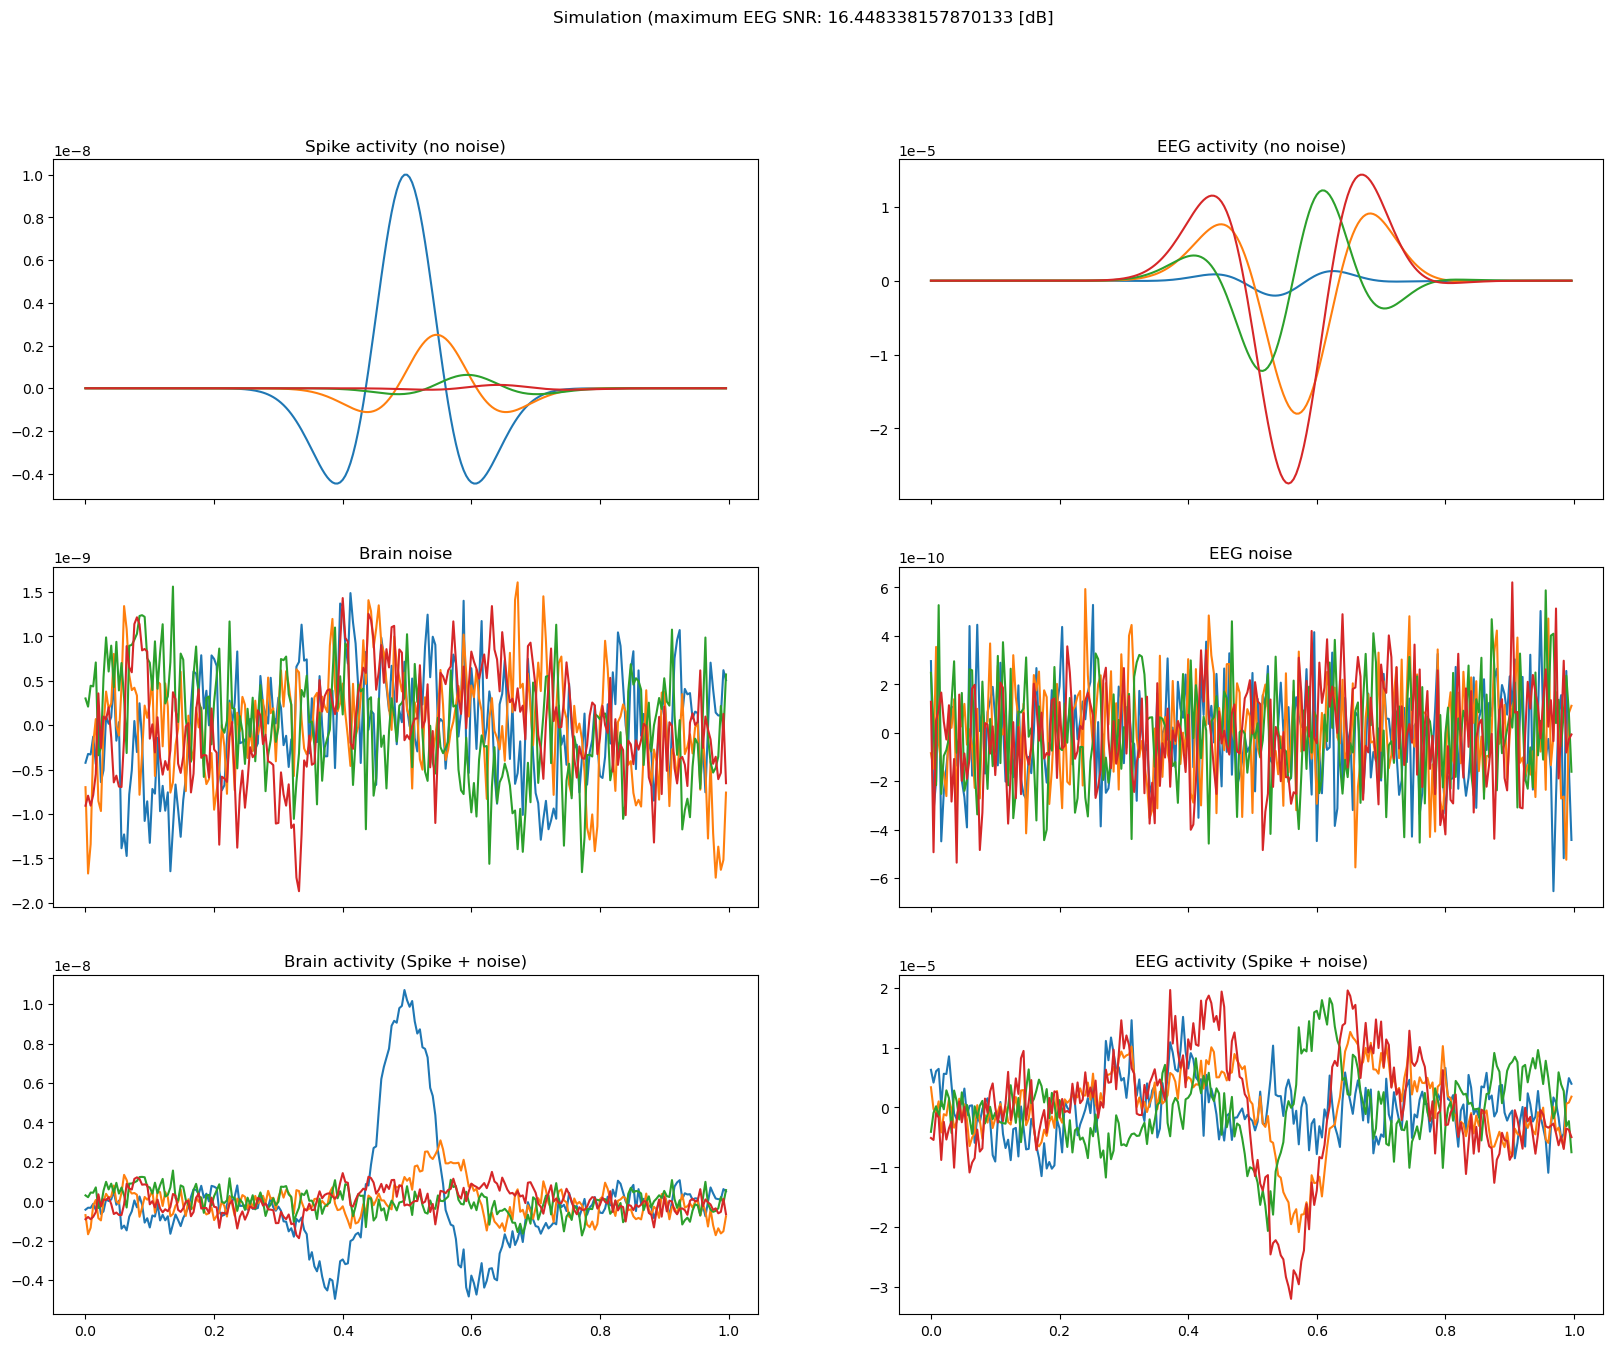

In [5]:
# function to select source, 1hop, 2hop ... 
peak_times = np.argmax(spike_activity, axis=1)
times      = np.unique(peak_times)

idx_brain = lambda i: np.argwhere(peak_times==times[i]).squeeze()[0]       # id of source (i=0), 1hop (i=1), 2hop (i=2) ...

# eeg without noise
_, eeg_clean = mm.utils.simulate_eeg(spike_activity, data["fwd"], data["eeg"], brain_noise=None, eeg_noise=None)
eeg_max = np.argsort(np.max(eeg_clean.data, axis=1))
idx_eeg = lambda i: eeg_max[30*i]

# compute SNR
Pspike = mm.utils.avg_power(A@spike_activity)
Pbrain = mm.utils.avg_power(A@brain_noise)
Peeg   = mm.utils.avg_power(eeg_noise)
SNR    = 10*np.log10(Pspike/(Pbrain+Peeg))

# plot figures
fig, axes = plt.subplots(3, 2, sharex=True, figsize=(20,15))
fig.suptitle(f"Simulation (maximum EEG SNR: {np.max(SNR):01} [dB]")

axes[0][0].set_title("Spike activity (no noise)")
for i in range(4):
    sns.lineplot(ax=axes[0][0], x=time, y=spike_activity[idx_brain(i),:])

axes[0][1].set_title("EEG activity (no noise)")
for i in range(4):
    sns.lineplot(ax=axes[0][1], x=time, y=eeg_clean.data[idx_eeg(i),:])

axes[1][0].set_title("Brain noise")
for i in range(4):
    sns.lineplot(ax=axes[1][0], x=time, y=brain_noise[idx_brain(i),:])

axes[1][1].set_title("EEG noise")
for i in range(4):
    sns.lineplot(ax=axes[1][1], x=time, y=eeg_noise[idx_eeg(i),:])

axes[2][0].set_title("Brain activity (Spike + noise)")
for i in range(4):
    sns.lineplot(ax=axes[2][0], x=time, y=brain.data[idx_brain(i),:])

axes[2][1].set_title("EEG activity (Spike + noise)")
for i in range(4):
    sns.lineplot(ax=axes[2][1], x=time, y=eeg.data[idx_eeg(i),:])


#### 🌟 Visualize Brain Activity

In [6]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], brain.data, sfreq=sfreq)

Widget(value='<iframe src="http://localhost:33609/index.html?ui=P_0x7604c1dc70e0_0&reconnect=auto" class="pyvi…

#### 🌟 Visualize background spectrum

In [7]:
spectrum = data["cst"] @ brain.data
mm.viz.plot_spectrum(spectrum[:, int(spectrum.shape[1]/2)])

#### 🌟 Visualize EEG Activity

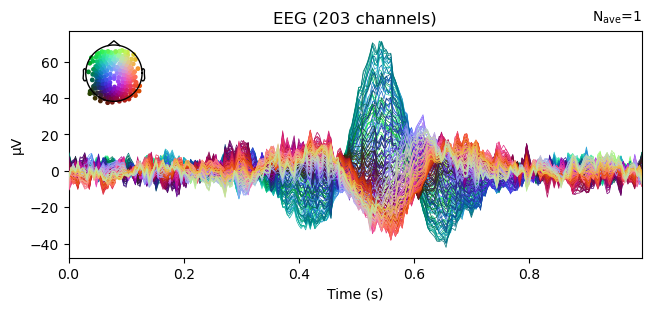

In [8]:
_ = eeg.plot()

# 

#### 🌟 Visualize EEG Topography

SNR topomap
Minimum SNR: -18.441797552839567
Maximum SNR: 16.448338157870133


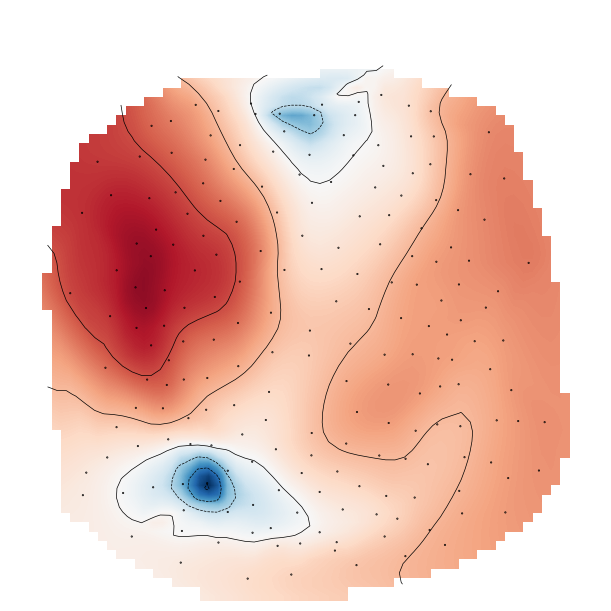

In [10]:
print(f"SNR topomap")
print(f"Minimum SNR: {np.min(SNR)}")
print(f"Maximum SNR: {np.max(SNR)}")
_ = mne.viz.plot_topomap(SNR, data["eeg"].info, size=6, outlines=None, extrapolate="local")